#Import Dependencies

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix,recall_score,f1_score,classification_report
from sklearn.metrics import roc_curve,roc_auc_score
from sklearn.metrics import precision_recall_curve,average_precision_score,accuracy_score,precision_score


Load Dataset

In [2]:
!ls

PS_20174392719_1491204439457_log.csv  sample_data


unzip the dataset

In [3]:
!unzip PS_20174392719_1491204439457_log.csv.zip

unzip:  cannot find or open PS_20174392719_1491204439457_log.csv.zip, PS_20174392719_1491204439457_log.csv.zip.zip or PS_20174392719_1491204439457_log.csv.zip.ZIP.


check

In [4]:
!ls

PS_20174392719_1491204439457_log.csv  sample_data


In [5]:
df=pd.read_csv('/content/PS_20174392719_1491204439457_log.csv')

In [6]:
#see 5 rows from starting
df.head(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0


#Dataset Summary:
#Features:
1. step=step tell us in which time transaction occure in  1 step means 1 hour 24 step means 1 day, not the number of transaction
* Why didn't they simply use 10:00 AM?
Because PaySim is a simulation, not a real bank database with actual calendar timestamps

2. type: what kind of financial transaction happened?

  * cash_in=money is added to an account
  * cash_out=money is taken out of an account.
  * DEBIT=money is debited/withdrawn from an account for a transaction.
  * PAYMENT=customer pays for something
  * TRANSFER=money is moved from on account to another account
3. amount=how much money was involved in that transaction
4. nameOrig: the id of the account/customer that started the transaction
c123456789 =123456789 is ID of the originating account
c= is used for customer accounts in paySim
5. oldbalanceOrg:the balance of the sender's account BEFORE the transaction.
6. newbalanceOrig:The sender's account balance After the transaction
7. nameDest: nameDest is the ID of the account receiving/being affected by the transaction
 * nameOrig
      * ↓
 * WHO started the transaction?

  * nameDest
      * ↓
* WHO is the destination?
* Customer A
   
    * ↓ ₹10,000
 * Customer B
* nameOrig = Customer A
* nameDest = Customer B
* amount   = 10000
8. oldbalanceDest:The destination account's balance BEFORE the transaction.
"""
* Sender:   Customer A
* Receiver: Customer B
* Amount:   ₹5,000"""
before receving the money customer B has:₹20,000
oldbalanceDest = ₹20,000

9. newbalanceDest=the destination/receiver's balance AFTER the transaction.
* ₹20,000 + ₹5,000
* = ₹25,000
10. isFraud=isFraud is not a normal input features we've learned so far
* isFraud = 0 -> Not fraud

* isFraud = 1 -> Fraud
11. isFlaggedFraud=It tells us that the existing rule catches only a small subset of suspicious behavior
* isFraud-> Ground-truth fraud label
* isFlaggedFraud ->Whether PaySim's existing rule flagged the transaction

#EDA

In [7]:
#check the shape
df.shape

(151799, 11)

there are 83561 rows are in this dataset
and 11 columns(features)

In [8]:
#info of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151799 entries, 0 to 151798
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            151799 non-null  int64  
 1   type            151799 non-null  object 
 2   amount          151799 non-null  float64
 3   nameOrig        151799 non-null  object 
 4   oldbalanceOrg   151799 non-null  float64
 5   newbalanceOrig  151798 non-null  float64
 6   nameDest        151798 non-null  object 
 7   oldbalanceDest  151798 non-null  float64
 8   newbalanceDest  151798 non-null  float64
 9   isFraud         151798 non-null  float64
 10  isFlaggedFraud  151798 non-null  float64
dtypes: float64(7), int64(1), object(3)
memory usage: 12.7+ MB


*  step,type,amount,nameOrig in this feature missing value is not present
 and remaining features have 1,1 missing value is present  

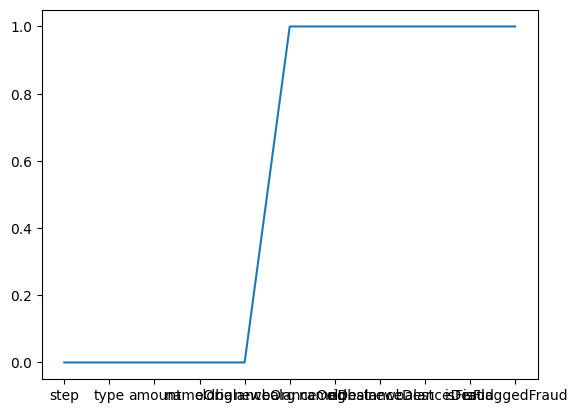

In [9]:
#missing value
df.isnull().sum()
plt.plot(df.isnull().sum())


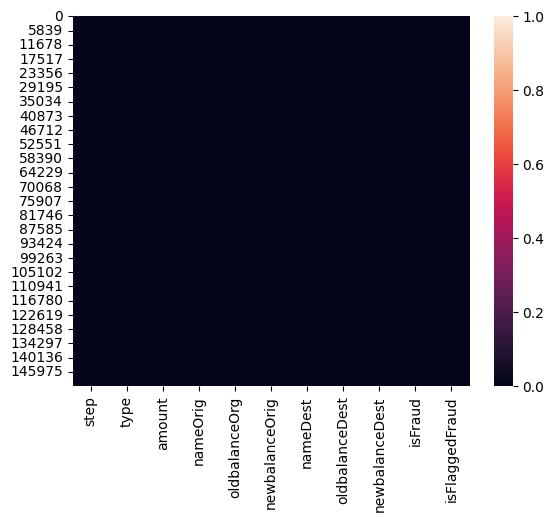

In [10]:
sns.heatmap(df.isnull())
plt.show()

In [11]:
df[df.isnull().any(axis=1)]

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
151798,12,PAYMENT,7513.74,C1069154168,6795.0,NaN,NaN,NaN,NaN,NaN,NaN


this data is missing(83560)

here whole transaction data is missing so ,decided to drop this


In [12]:
#drop the missing transaction
df = df.dropna()

In [13]:
df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 151798 entries, 0 to 151797
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            151798 non-null  int64  
 1   type            151798 non-null  object 
 2   amount          151798 non-null  float64
 3   nameOrig        151798 non-null  object 
 4   oldbalanceOrg   151798 non-null  float64
 5   newbalanceOrig  151798 non-null  float64
 6   nameDest        151798 non-null  object 
 7   oldbalanceDest  151798 non-null  float64
 8   newbalanceDest  151798 non-null  float64
 9   isFraud         151798 non-null  float64
 10  isFlaggedFraud  151798 non-null  float64
dtypes: float64(7), int64(1), object(3)
memory usage: 13.9+ MB


In [15]:
df.duplicated().sum()

np.int64(0)

* there is no duplicate value present in this dataset

In [16]:
#transaction types
df.type.value_counts()

,count
type,
PAYMENT,57888
CASH_OUT,48858
CASH_IN,30820
TRANSFER,12851
DEBIT,1381


transaction type has an uneven distribution
payment is very common
DEBIT relatively rare

In [17]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,151798.000000,1.517980e+05,1.517980e+05,1.517980e+05,1.517980e+05,1.517980e+05,151798.000000,151798.0
mean,9.333885,1.791786e+05,8.879167e+05,9.043402e+05,9.137641e+05,1.180076e+06,0.000863,0.0
std,1.906275,3.401614e+05,2.807540e+06,2.844268e+06,2.384389e+06,2.705635e+06,0.029364,0.0
min,1.000000,3.200000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
25%,9.000000,1.111407e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
50%,10.000000,6.123069e+04,1.999050e+04,0.000000e+00,3.164400e+04,9.332977e+04,0.000000,0.0
75%,11.000000,2.230429e+05,1.956688e+05,2.262719e+05,6.869059e+05,1.120989e+06,0.000000,0.0
max,12.000000,1.000000e+07,3.893942e+07,3.894623e+07,3.490552e+07,3.894623e+07,1.000000,0.0


In [18]:
def cat_visualize(df,column):

  print(f"visualization of {column}")
  if df[column].dtype =="object" and column not in  ["nameOrig", "nameDest"]:
    print("\nValue Counts:")
    print(df[column].value_counts)

    plt.figure(figsize=(6,4))
    df[column].value_counts().plot(kind='bar')
    plt.title(f"bar chart of {column}")
    plt.xlabel(column)
    plt.ylabel("count")
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()

visualization of step
visualization of type

Value Counts:
<bound method IndexOpsMixin.value_counts of 0          PAYMENT
1          PAYMENT
2         TRANSFER
3         CASH_OUT
4          PAYMENT
            ...   
151793     PAYMENT
151794     PAYMENT
151795     PAYMENT
151796     PAYMENT
151797     PAYMENT
Name: type, Length: 151798, dtype: object>


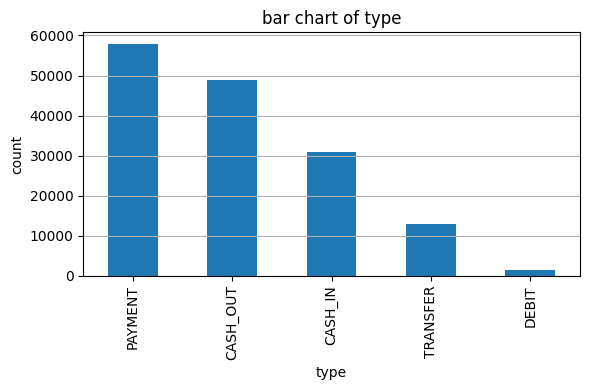

visualization of amount
visualization of nameOrig
visualization of oldbalanceOrg
visualization of newbalanceOrig
visualization of nameDest
visualization of oldbalanceDest
visualization of newbalanceDest
visualization of isFraud
visualization of isFlaggedFraud


In [19]:
for col in df.columns:
  cat_visualize(df,col)

In [20]:
#Visualization
def visualization(df,column):
  print("-"*30)

  if df[column].dtype=="float64":
    #histogram
    print("\nHistogram")

    plt.figure(figsize=(6,4))
    plt.hist(df[column],bins=15)
    plt.title(f"histogram of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    #kde plot

    print("/nKDE plot")

    plt.figure(figsize=(6,4))
    df[column].plot(kind='kde')
    plt.title(f"kde plot of {column}")
    plt.xlabel(column)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    #skewness

    print("\nSkewness:")

    plt.figure(figsize=(6,4))
    print(df[column].skew())

    #boxplot

    print("\nBox Plot")

    plt.figure(figsize=(6,4))
    df[column].plot(kind='box')
    plt.title(f"box plot of {column}")
    plt.ylabel(column)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

------------------------------

Histogram


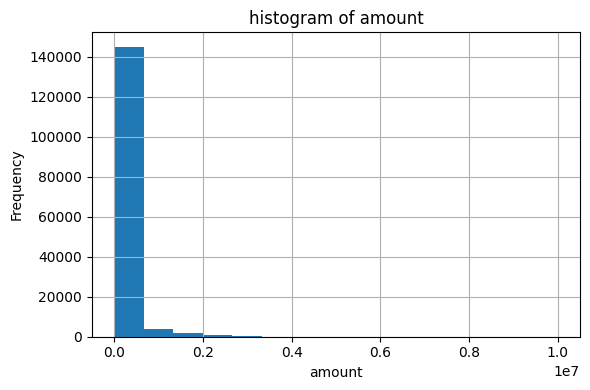

/nKDE plot


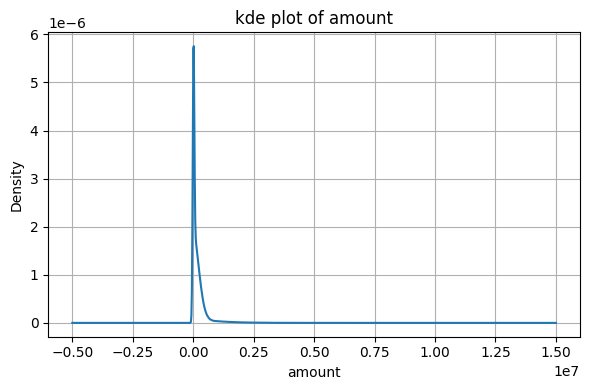


Skewness:
5.1832978412108055

Box Plot


<Figure size 600x400 with 0 Axes>

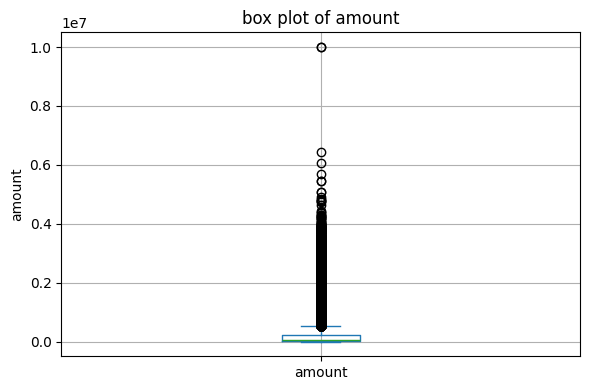

In [21]:
visualization(df, "amount")

**amount**:histogram-The Amount Feature Is highly Right-Skewed.Most transaction have relatively small amounts while a small number of transaction amount may be unusual,although they are not automatically fraudulent.
* A very large number of transaction are concentrated in the 0=2 million range while transaction above range becomes much less frequent

*   Skewness between -0.5 and 0.5 → Approximately symmetric


*   Skewness between -1 and -0.5 or 0.5 and 1 → Moderately skewed

*   Skewness less than -1 or greater than 1 → Highly skewed


1. 15739 transaction happend at 11 steps
2. 5501 rows means are cash_out transactions in the subset
3. 2504 rows amount>200000

In [22]:
df[(df["amount"] > 200000) & (df["step"] == 11) & (df['type']=="CASH_OUT")]

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
108717,11,CASH_OUT,361489.71,C1721094820,19111.0,0.0,C1131138067,0.00,13277.21,0.0,0.0
108718,11,CASH_OUT,490908.50,C303404123,14688.0,0.0,C483370168,46331.87,537240.36,0.0,0.0
108724,11,CASH_OUT,816078.18,C1224910336,67097.0,0.0,C1541125198,0.00,2337723.27,0.0,0.0
108725,11,CASH_OUT,538576.41,C1966798141,661.0,0.0,C630085121,0.00,368058.75,0.0,0.0
108732,11,CASH_OUT,497753.33,C1545886707,31831.0,0.0,C1881960472,712694.47,2288249.41,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
145791,11,CASH_OUT,568150.79,C865093388,3533.0,0.0,C1372252045,0.00,704889.01,0.0,0.0
145793,11,CASH_OUT,470236.72,C2047120071,15175.0,0.0,C1955768822,178448.02,648684.74,0.0,0.0
145944,11,CASH_OUT,220943.96,C597904281,117.0,0.0,C1611625950,78649.21,299593.17,0.0,0.0
145950,11,CASH_OUT,315387.97,C550380414,11352.0,0.0,C1181579840,6293014.58,6534852.93,0.0,0.0


In [23]:
df[(df["type"] == "CASH_OUT") & (df["amount"] == 1.000000e+07)]

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
4441,4,CASH_OUT,10000000.0,C351297720,10000000.0,0.0,C766681183,0.0,9941904.21,1.0,0.0


row 4441 are with high amount and old balance is 10000000 and it send to anothers account and their balnce is 0 and now reciever new balance is 9941904.21	and flagged is 1 but isflaggedFrud is zero


In [24]:
df['amount'].describe()

,amount
count,1.517980e+05
mean,1.791786e+05
std,3.401614e+05
min,3.200000e-01
25%,1.111407e+04
50%,6.123069e+04
75%,2.230429e+05
max,1.000000e+07


in amount column many outliers are present but they are genuine transcation


------------------------------

Histogram


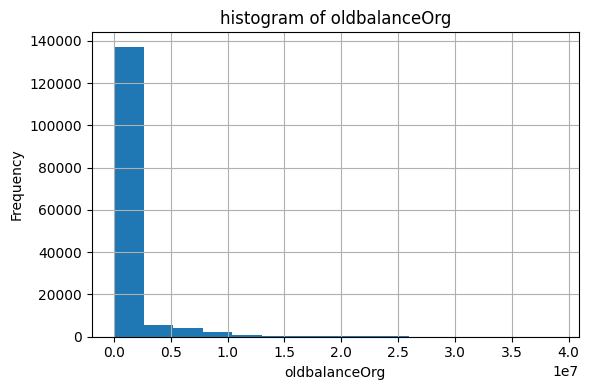

/nKDE plot


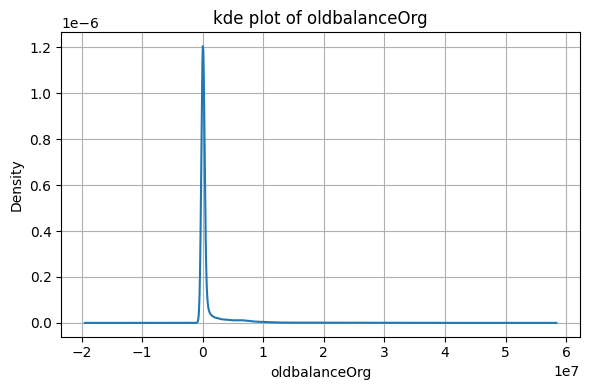


Skewness:
5.268046156100875

Box Plot


<Figure size 600x400 with 0 Axes>

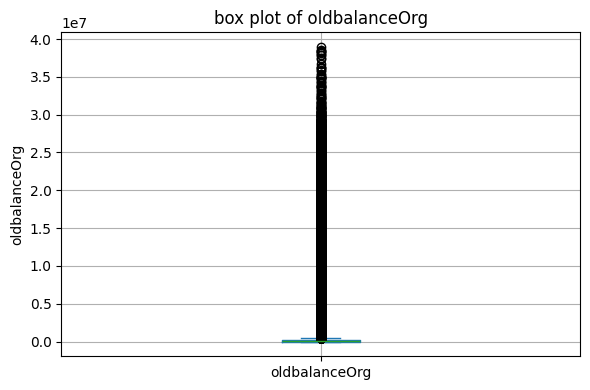

In [25]:
visualization(df,'oldbalanceOrg')

"oldbalanceOrg":
25k is NOT the balance.

It is the number of transactions.
1. A large number of transaction have sender balance between 0 to 5 million before the transaction.

25K frequency ~25,000 transactions, in the first balance range, that range is near the lower end
, many transactions have low sender balances, bars decrease toward right , fewer transactions have high sender balances , long right tail, right skewed distribution

2. this feature is very skewed 3.8883 -> strongly positive -> long right tail -> many smaller values + fewer very large values
 oldbalanceOrg is strongly right-skewed .most transactions involve relatively small sender balances,while a smaller number have very large sender balance ,,,Skewness isn't telling you whether the feature is good or bad.
It's telling you how the values are distributed

3. box plot:  
* many values concentrated at the lower end
* a long tail
* strong potive skweness

so, boxplot outlier is not wrong data
in finanacial dataset a sender having a very large balance can be completlely legitimate
                              


------------------------------

Histogram


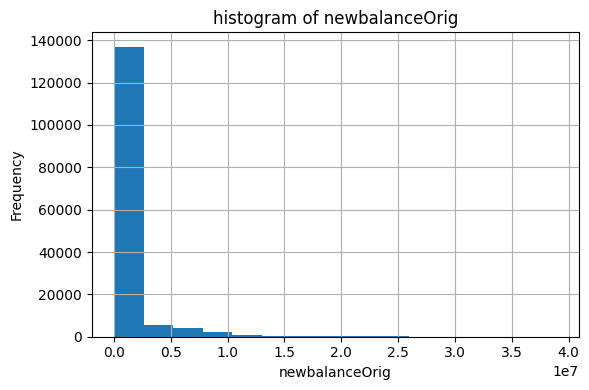

/nKDE plot


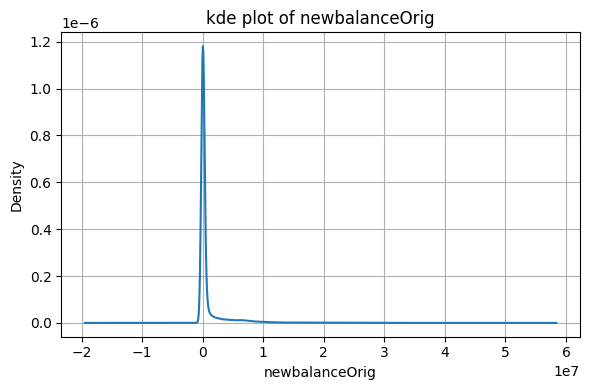


Skewness:
5.198193611385573

Box Plot


<Figure size 600x400 with 0 Axes>

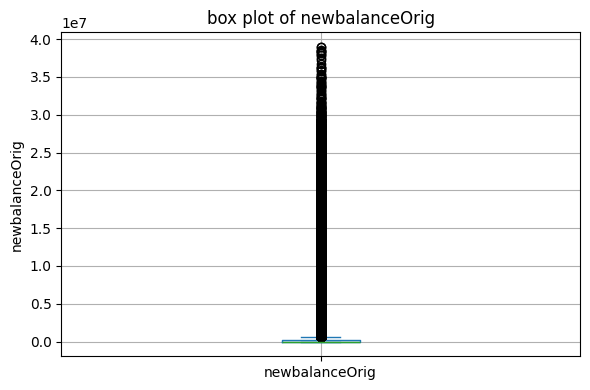

In [26]:
visualization(df,"newbalanceOrig")

"**Histogram**":we see our ovservation in left side lower values new balance of the senderrelatively very small
newbalanceorig is heavily concentrated at lower values most,transactions have relatively small sender balances after the transaction while transactions with very large new sender balance occure less frequently
* transactions with large newbalanceOrig values occur less frequently. data are streched toward that is right skewed

**skew**:data are highly skewed we see in graph tail are toward in right many small values is in left side og new balnce of origin

**box plot**: Boxplot: Many observations appear beyond the upper whisker, indicating statistical outliers according to the IQR rule. Since these values can represent genuine financial transactions, they should not be removed automatically

------------------------------

Histogram


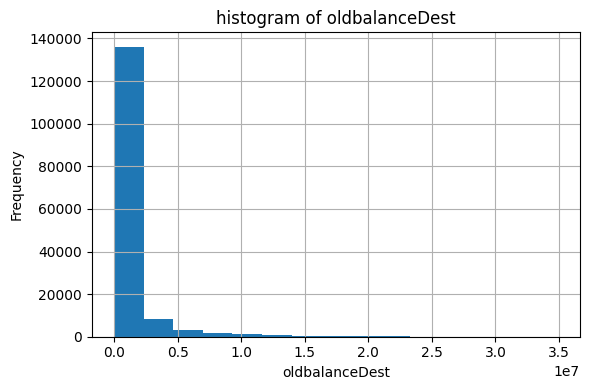

/nKDE plot


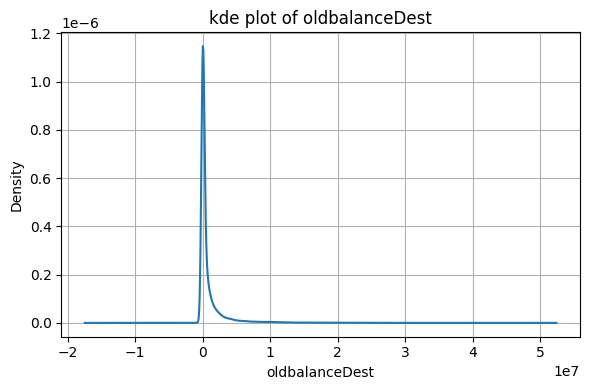


Skewness:
5.085475120706026

Box Plot


<Figure size 600x400 with 0 Axes>

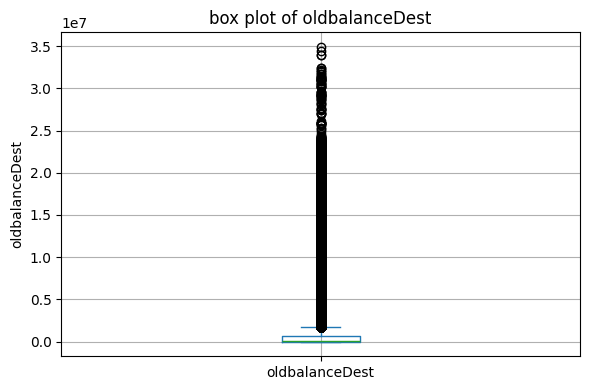

In [27]:
visualization(df,"oldbalanceDest")

**histogram**:
frequency no of transaction,
Frequency = number of rows/observations in that bin,1 row = 1 transaction
* rought 800000 transactions fall into that oldbalanceDest balance range, most transaction have relatively small receiver balances before th transaction with very large receiver balances occur much less frequently

**skew**: it strongly right skewed

**boxplot**many oversavation appear widhker ,indicating statistical outliers according to the IQR rule .since these values

------------------------------

Histogram


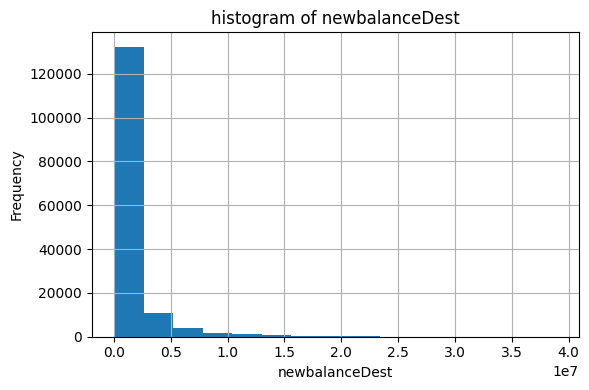

/nKDE plot


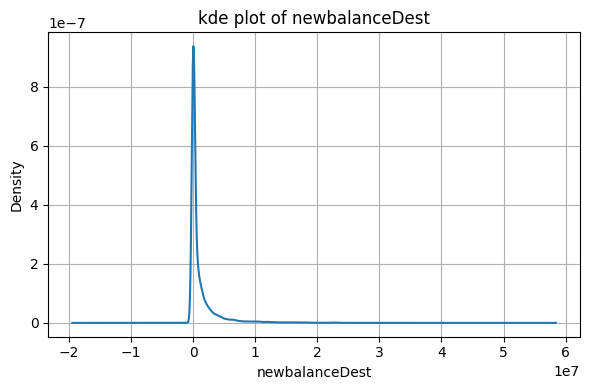


Skewness:
4.438507605322791

Box Plot


<Figure size 600x400 with 0 Axes>

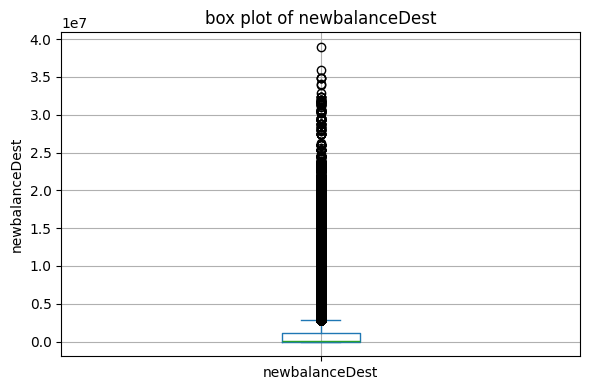

In [28]:
visualization(df,"newbalanceDest")

**histogram**: roughly 800000 transaction fall in newbalnceDest range most of the transaction is receive very small and less large amount
The distribution is heavily concentrated at lower newbalanceDest values. A large number of transactions have relatively small receiver balances after the transaction, while transactions with very large receiver balances occur less frequently

**skew**: it strongly right skewed

**boxplot**many oversavation appear widhker ,indicating statistical outliers according to the IQR rule .since these values

In [29]:
df.select_dtypes("object").columns

Index(['type', 'nameOrig', 'nameDest'], dtype='object')

<Axes: xlabel='type'>

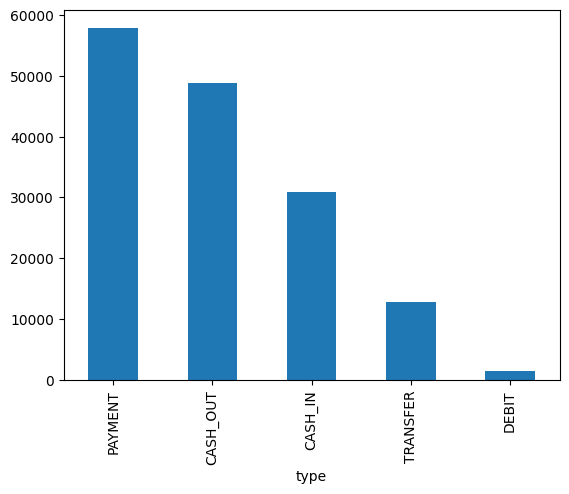

In [30]:
df['type'].value_counts().plot(kind='bar')

type= Payment  is the most frequent transaction type,while debit is the least frequent CASH_OUT and CASH_IN occur more frequently than transfer

,count
isFraud,
0.0,151667
1.0,131


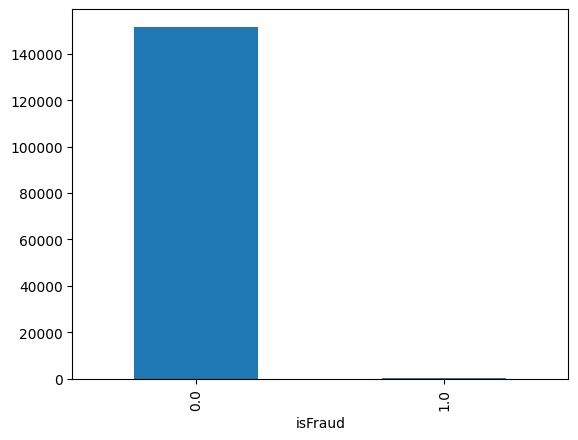

In [31]:
df['isFraud'].value_counts().plot(kind='bar')
df['isFraud'].value_counts()

isFraud= isFraude is highly imbalanced.the vast majority os transactions are non-fraudulent (0),while fraudulent transaction(1) represent very small portion of the dataset
* imbalanced feature

isFlaggedFraud
0.0    151798
Name: count, dtype: int64


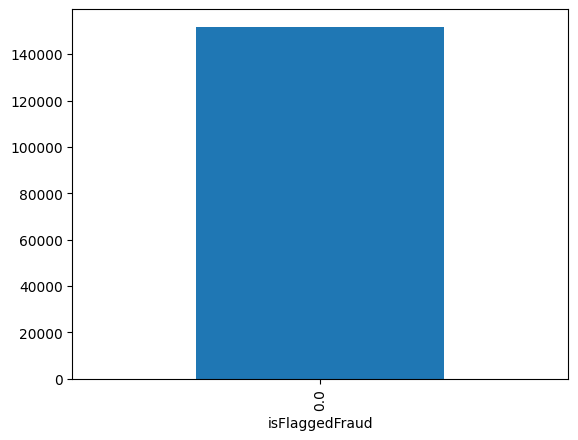

In [32]:
df['isFlaggedFraud'].value_counts().plot(kind='bar')
print(df['isFlaggedFraud'].value_counts())

isFlaggedFraud=None of the transactions in this dataset were flagged by PaySim's isFlaggedFraud rule
* isFlaggedFraud contains only the value 0 in the analyzed data, meaning none of these transactions were flagged by the existing rule-based fraud detection system. This should not be interpreted as meaning that there was no fraud, because isFraud is the actual fraud label.

#**Bivarient Relationship**

numerical<->numerical

In [33]:
df.head(1)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0


<Axes: xlabel='oldbalanceOrg', ylabel='amount'>

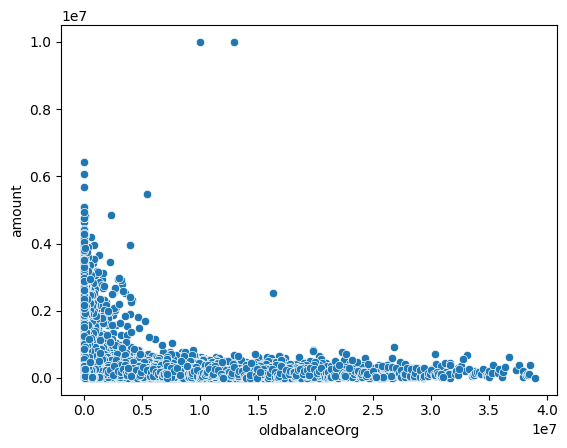

In [34]:
sns.scatterplot(data=df,x="oldbalanceOrg", y="amount")

the Scatter plot does not show a clear simple linear relationship between sendwr before transaction(oldbalanceorg) and the transferred (amount).most observationare at lower values while a small no of transactions have unusually large amount

**NOTE**:oldbalanceOrg~=0
many transactions occure when the sendwr'recorded balance before transaction is very small or zero.

but notice that some of those transactions still have non-zero amounts
(investigate)


* X-axis: oldbalanceOrg
        ↓
1.How much balance the sender had   BEFORE the transaction?

* Y-axis: amount
        ↓
2.How much money was transferred in that transaction?

*1. for hue*=***isFraud***

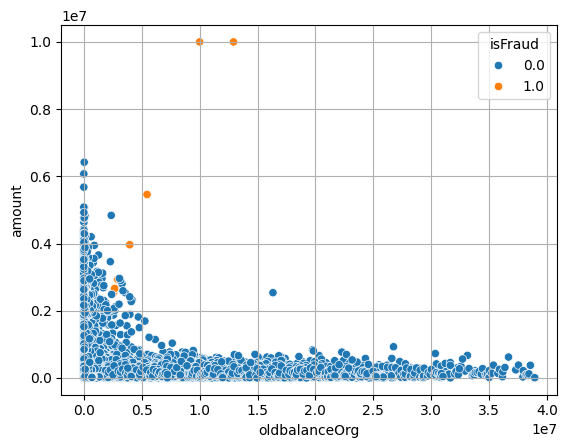

In [35]:
sns.scatterplot(data=df,x="oldbalanceOrg",y="amount",hue="isFraud")
plt.grid(True)
plt.show()

the scatter plot shows the relationship between the sender's balance before the transaction (oldbalanceOrg) and the transaction amount. Most transactions are concentrated in the lower range of both variables. Fraudulent transactions are relatively rare and appear as isolated observations. Some fraudulent transactions involve very large transaction amounts, but large legitimate transactions are also present. Therefore, transaction amount alone does not clearly separate fraudulent and legitimate transactions.

In [36]:
df["amount_ratio"]=df["amount"]/(df["oldbalanceOrg"]+1)

<Axes: xlabel='isFraud', ylabel='amount_ratio'>

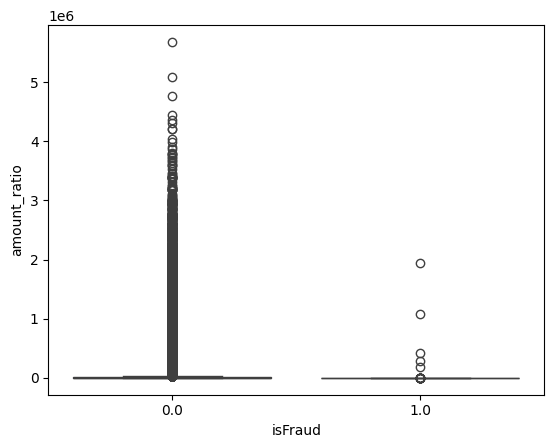

In [37]:
sns.boxplot(data=df,x="isFraud",y="amount_ratio")

this box plot repsent is fraude in amount_ratio in this box plot fraud ratio is very low as compare to not fraud paysim detection ,outliers are present

**oldbalanceOrg vs newbalanceOrig**

<Axes: xlabel='oldbalanceOrg', ylabel='newbalanceOrig'>

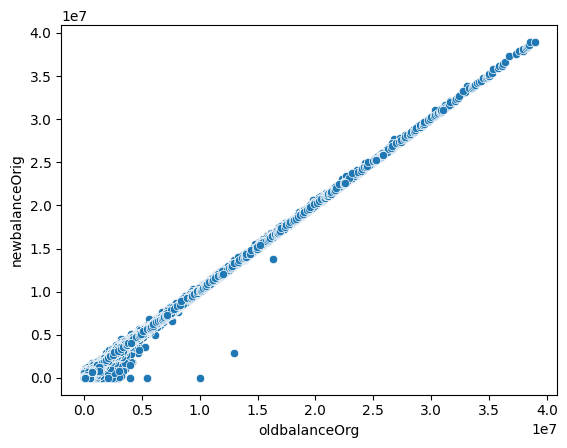

In [38]:
sns.scatterplot(data=df,x="oldbalanceOrg",y="newbalanceOrig")

the scatter plot shows the relationship between the  before sender's balance(oldbalanceOrg) and after sender balance (newbalanceOrg) .here strong positive relationship between oldbalanceOrg and newbalanceOrig . a large concentration exists near zero, while some observation show large decrease in balance and appear outliers .those are not in diagnoal we se huge difference between before and after, we see with hue parameter

<Axes: xlabel='oldbalanceOrg', ylabel='newbalanceOrig'>

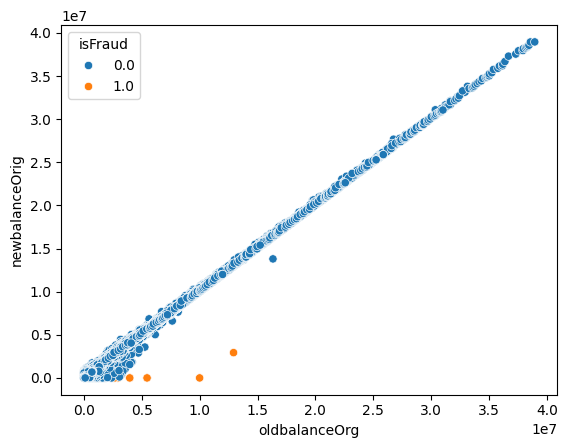

In [39]:
sns.scatterplot(data=df,x="oldbalanceOrg",y="newbalanceOrig",hue="isFraud")

this scatterplot show the relationship between before sender amount(oldbalanceorg) and after transaction amount (newbalanceOrg) with hue parameter very strong positive relationship and some are not in diagonal those are fraud in hue parameter

#balance change

In [40]:
df["balance_change"]=df["oldbalanceOrg"]-df["newbalanceOrig"]

In [41]:
df["balance_change"]

,balance_change
0,9839.64
1,1864.28
2,181.00
3,181.00
4,11668.14
...,...
151793,6266.61
151794,21278.77
151795,7131.13
151796,2870.85


#compare

<Axes: xlabel='amount', ylabel='balance_change'>

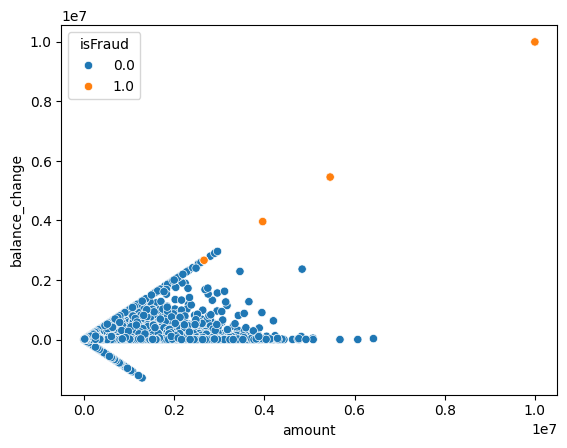

In [42]:
sns.scatterplot(data=df,x="amount",y="balance_change",hue="isFraud")

this scatterplot show the relationship amount and balance_change blue is represent isfraude =0 non-fraud transactions ,Orange isFraude =1 fraude transaction ,most oversavation are non-fraud transaction most are in lower-left region,orange points are very few dataset are imbalanced.orange points are located relatively large amount and balance_change values

#transaction_type <-> amount

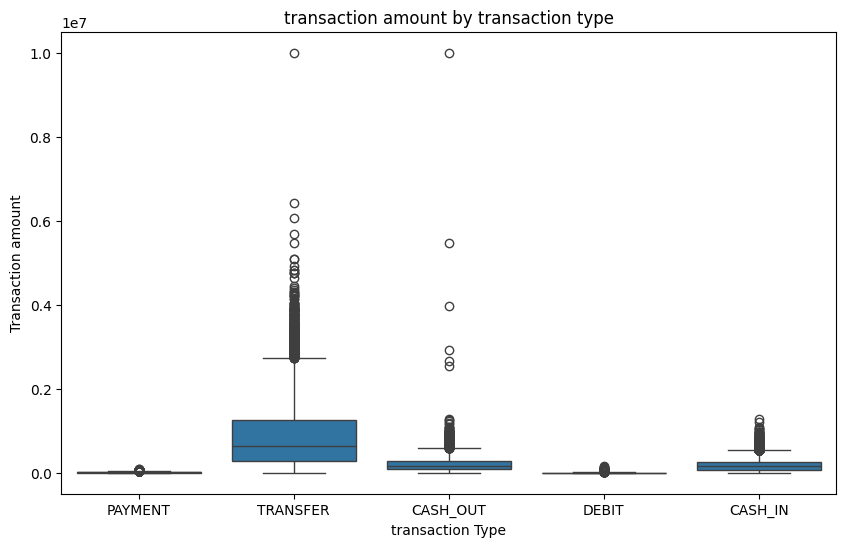

In [43]:
plt.figure(figsize=(10,6))

sns.boxplot(data=df,x="type",y="amount")
plt.xlabel("transaction Type")
plt.ylabel("Transaction amount")
plt.title("transaction amount by transaction type")

plt.show()

* small box=most of the middle transactions have similar amounts
* Big box= the middle transactions have more variation in amount

1. big box=more variability
2. small box= less variability

* this graph shows diiferent transaction amount are distributed very differently across transaction type

1. transafer spread is largest in this graph have much variability in transacion amount than payment transaction
2.This graph compares how much money is involved in different types of transactions.
Payment transactions usually involve smaller and more similar amounts. This is why their box is small and close to the bottom.
Transfer transactions involve much larger amounts and the amounts vary a lot. We can also see many transactions that are unusually large, with some reaching around 10 million.
Cash-out transactions also involve larger amounts than normal payments and have several unusually large transactions.
Debit transactions generally involve smaller and more consistent amounts, similar to payments.
Cash-in transactions are generally larger than payments and show more variation.
Overall, the graph tells us that the type of transaction is related to how much money is being moved. Transfers and cash-outs tend to involve larger and more varied amounts, while payments and debits are generally smaller and more consistent.

#correlation analysis

**interpretation**
1. transaction amount and transcation ratio 0.53 which indicate positive relationship
2. heatmap shows shows that the sender's and receiver's balances have strong positive relationships with their respective balances after transactions. Most other relationships are weak or moderate

<Axes: >

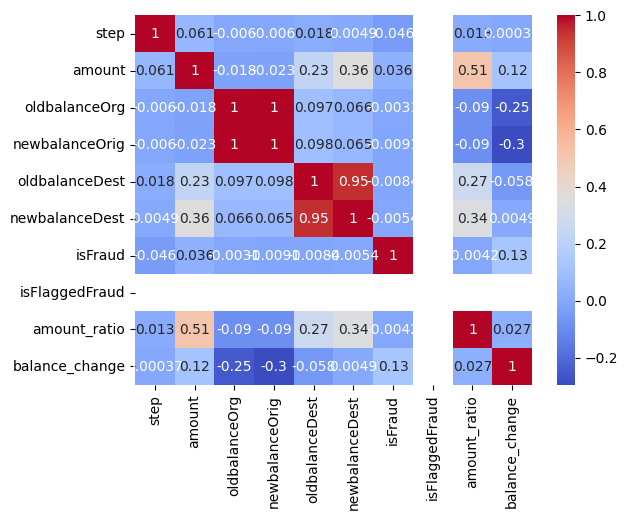

In [44]:
corr=df.select_dtypes("number").corr()
sns.heatmap(corr,annot=True,cmap="coolwarm")

#fraud analysis

1. this graph shows which transaction types have a higher percentage of fraudulent transaction
2. steps graoup transaction by type-> calculate avg of isfraud-> multiply 100(convert the porportion to a percentage)->barchar
3. more highest rate of fraude approx 0.35% peak bar is transfer fraude happen more transaction. this means around 0.35 out of every 100 transaction are fraudulent
4. and then cashout second highest 0.09
5. payment ,cash_in and debit :their fraud rates are approximately zero in this graph

type
CASH_IN     0.000000
CASH_OUT    0.135085
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.505797
Name: isFraud, dtype: float64


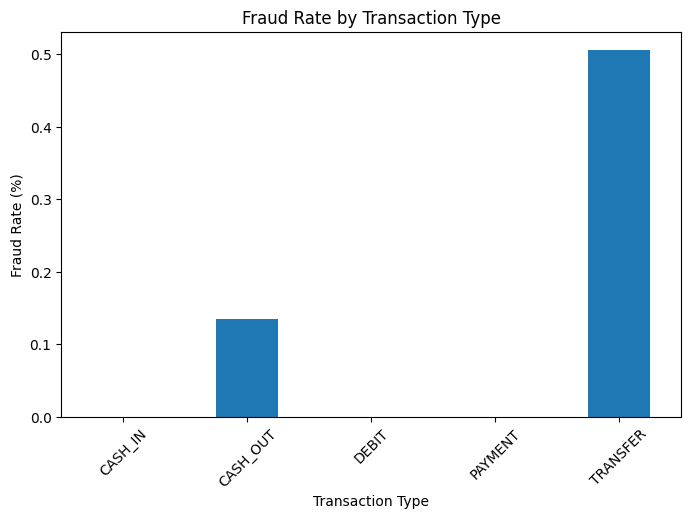

In [45]:
fraud_rate = df.groupby("type")["isFraud"].mean() * 100
print(fraud_rate)
fraud_rate.plot(kind="bar", figsize=(8, 5))
plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.show()

x- axis: it represrnt fraude status
y-axis: it represent transaction amt
1. fraud 0 width is thin as compare to 1 and to may outlier are present
2. 1 has more width as compare to 0 and leass outlier present

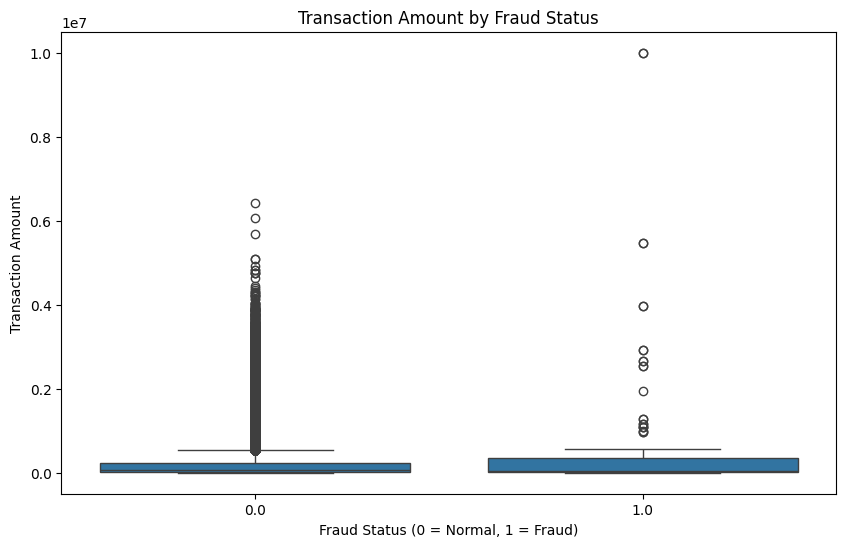

In [46]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="isFraud", y="amount")
plt.xlabel("Fraud Status (0 = Normal, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount by Fraud Status")
plt.show()

#investigate transaction type

* amount alone doean't clearly seprate fraud from normal transactions.
* transaction type help us identify which type have  higher rates of fraude rates

**interpretation**:
1. x-axis:transaction type-PAYMENT, TRANSFER, CASH_OUT, DEBIT, and CASH_IN
2. y-axis:transaction amount.
3. blue boxes:normal transactions (isFraud=0)
4. orange boxes:fraudulent transaction(isfraud=1)
5. transfer: the normal transaction have higher middle amt than the fraudulent transaction, amounts overlap and both groups contain usually large transactions
6. cash_out: these two groups have overlapping amounts. fraudulents transactions appear to have wider spread in their middle amt .
7. payment and debit: there is no clearly visible orange fraud box for these types
8. cash in: this graph shows normal transctions but no visible fraudulent group

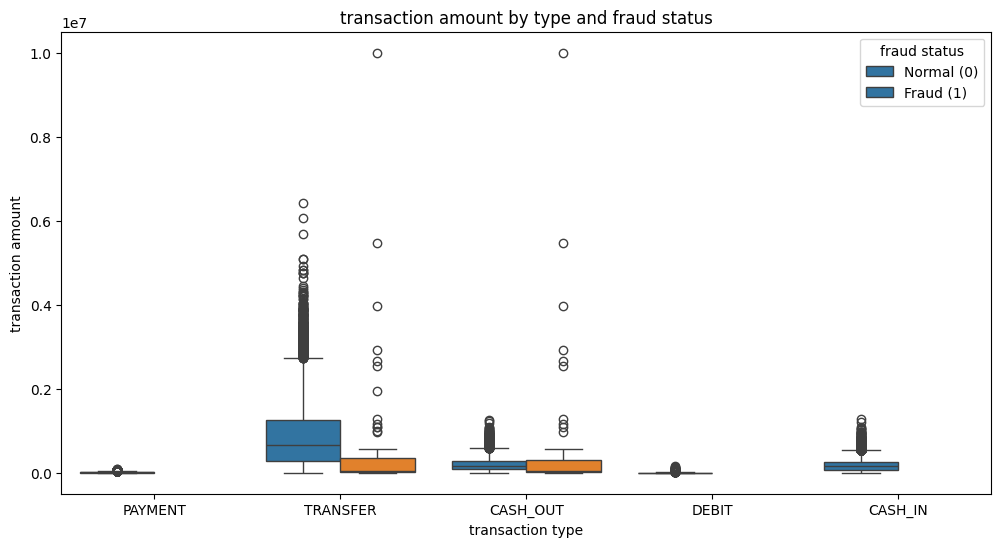

In [47]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df,x="type",y="amount",hue="isFraud")
plt.title("transaction amount by type and fraud status")
plt.xlabel("transaction type")
plt.ylabel("transaction amount")
plt.legend(title="fraud status",labels=["Normal (0)","Fraud (1)"])
plt.show()

**transaction types actually contain fraud**
1. know where fraud occurs and how many fraudulent transactions we have in each type

**interpretation**:
1. here we see cash_out 48792/66 and transfer 12786/65
2. cash_out and transfer are appear in fraud observation and cash_in and debit , payment are zero involved

In [48]:
pd.crosstab(df["type"],df["isFraud"])

isFraud,0.0,1.0
type,,
CASH_IN,30820,0
CASH_OUT,48792,66
DEBIT,1381,0
PAYMENT,57888,0
TRANSFER,12786,65


fraudulent transaction appear in cash_out , transfer

In [49]:
df[df["isFraud"]==1]["type"].value_counts()

,count
type,
CASH_OUT,66
TRANSFER,65


In [50]:
df[["oldbalanceOrg","newbalanceOrig","amount","isFraud","balance_change"]].head()

,oldbalanceOrg,newbalanceOrig,amount,isFraud,balance_change
0,170136.0,160296.36,9839.64,0.0,9839.64
1,21249.0,19384.72,1864.28,0.0,1864.28
2,181.0,0.00,181.00,1.0,181.00
3,181.0,0.00,181.00,1.0,181.00
4,41554.0,29885.86,11668.14,0.0,11668.14


In [51]:
# check the entire dataset
df["balance_difference"]=(df["balance_change"]-df["amount"])
df["balance_difference"].describe()

,balance_difference
count,1.517980e+05
mean,-1.956020e+05
std,3.509308e+05
min,-6.388051e+06
25%,-2.599761e+05
50%,-4.736386e+04
75%,-1.673470e-10
max,1.000000e-02


In [52]:
df["balance_difference"].head(3)

,balance_difference
0,1.455192e-11
1,-1.136868e-12
2,0.000000e+00


In [53]:
df[df["balance_difference"]==1.000000e-02]

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,amount_ratio,balance_change,balance_difference


1. 8. the account had 2671 but the transaction amount was 4024  the transaction amount was 1353 more than the original balance

In [54]:
df[[
    "oldbalanceOrg",
    "amount",
    "newbalanceOrig"
]].head(10)

,oldbalanceOrg,amount,newbalanceOrig
0,170136.00,9839.64,160296.36
1,21249.00,1864.28,19384.72
2,181.00,181.00,0.00
3,181.00,181.00,0.00
4,41554.00,11668.14,29885.86
5,53860.00,7817.71,46042.29
6,183195.00,7107.77,176087.23
7,176087.23,7861.64,168225.59
8,2671.00,4024.36,0.00
9,41720.00,5337.77,36382.23


**Transaction amount > Original account balance**

In [55]:
df["amount_greater_than_balance"]=(df["amount"]>df["oldbalanceOrg"])


here amount_greater_than_balance false 30673 it means amount is not greater than oldbalance not fraud count is 30570 and fraud count is 103
* but where true is 39184 data are true amount is greater than amount and not fraud count is 39180 and fraud count is 4

In [56]:
#crosstab
pd.crosstab(df["amount_greater_than_balance"],df["isFraud"])

isFraud,0.0,1.0
amount_greater_than_balance,,
False,62236,125
True,89431,6


1. here expected amount is negative because the transaction amount is greater than original balance but the new balance show 0

In [57]:
df["expected_balance"]=(df["oldbalanceOrg"]-df["amount"])
df[["oldbalanceOrg","amount","newbalanceOrig","expected_balance","isFraud"]].head(20)

,oldbalanceOrg,amount,newbalanceOrig,expected_balance,isFraud
0,170136.00,9839.64,160296.36,160296.36,0.0
1,21249.00,1864.28,19384.72,19384.72,0.0
2,181.00,181.00,0.00,0.00,1.0
3,181.00,181.00,0.00,0.00,1.0
4,41554.00,11668.14,29885.86,29885.86,0.0
5,53860.00,7817.71,46042.29,46042.29,0.0
6,183195.00,7107.77,176087.23,176087.23,0.0
7,176087.23,7861.64,168225.59,168225.59,0.0
8,2671.00,4024.36,0.00,-1353.36,0.0
9,41720.00,5337.77,36382.23,36382.23,0.0


* here balance_mismatch true data is 55824 and false mismatch data is 14033

In [58]:
df["balance_mismatch"]=(df["expected_balance"]!=df["newbalanceOrig"])
df["balance_mismatch"].value_counts()

,count
balance_mismatch,
True,124718
False,27080


* balance_mismatch false count is 14033 and not fraud is 13932 and fraud detected count is 101 and true balance_mismatch is true count is 55824 and not fraud is 55818 and fraud count is 6

In [59]:
#crosstab
pd.crosstab(df["balance_mismatch"],df["isFraud"])

isFraud,0.0,1.0
balance_mismatch,,
False,26957,123
True,124710,8


#data leakage

In [60]:
#check columns
df.columns.tolist()

['step',
 'type',
 'amount',
 'nameOrig',
 'oldbalanceOrg',
 'newbalanceOrig',
 'nameDest',
 'oldbalanceDest',
 'newbalanceDest',
 'isFraud',
 'isFlaggedFraud',
 'amount_ratio',
 'balance_change',
 'balance_difference',
 'amount_greater_than_balance',
 'expected_balance',
 'balance_mismatch']

In [61]:
df[["amount_ratio"]].head()

,amount_ratio
0,0.057834
1,0.087731
2,0.994505
3,0.994505
4,0.280788


#time-based analysis

1. how transaction activity and fraud changes overtime using the step column in this dataset

**step**:min time step is 1 means 1 hr and max is 11 (11 hr)

In [62]:
#describe step
df["step"].describe()

,step
count,151798.000000
mean,9.333885
std,1.906275
min,1.000000
25%,9.000000
50%,10.000000
75%,11.000000
max,12.000000


**interpretation**:
1. here x represent time step
2. and y represent transaction
3. steps 1-6 transaction volume is relatively low
4. step 9-10 transaction volume reaches its heighest levwl at approximately 37000 in step 9
5. step 11 gradually drop

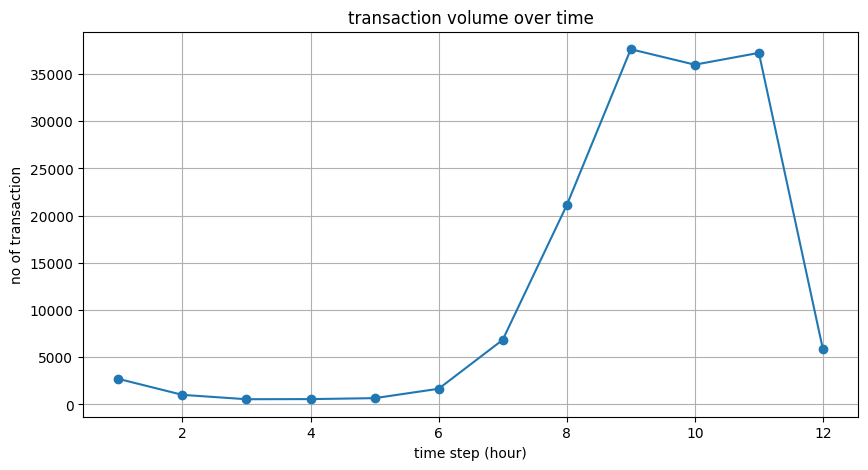

In [63]:
transaction_per_step=df["step"].value_counts().sort_index()
transaction_per_step.plot(kind="line",marker='o',figsize=(10,5))
plt.title("transaction volume over time")
plt.xlabel("time step (hour)")
plt.ylabel("no of transaction")
plt.grid(True)
plt.show()


#fraud rate over time

**interpretation**:
X-axis: Represents the simulation time step (step), where each step corresponds to one hour in the simulation.



Y-axis: Represents the fraud rate as a percentage of all transactions at that step.



Steps 1–3: The fraud rate fluctuates slightly increasing at Step 2 and decreasing at Step 3.



Step 4: The fraud rate reaches its highest point, at approximately 1.77%.



Steps 5–6: The rate decreases to around 0.90% at Step 5, then rises to approximately 1.32% at Step 6.



Steps 7–11: The fraud rate drops sharply at Step 7 and continues declining, approaching 0% by Step 11.

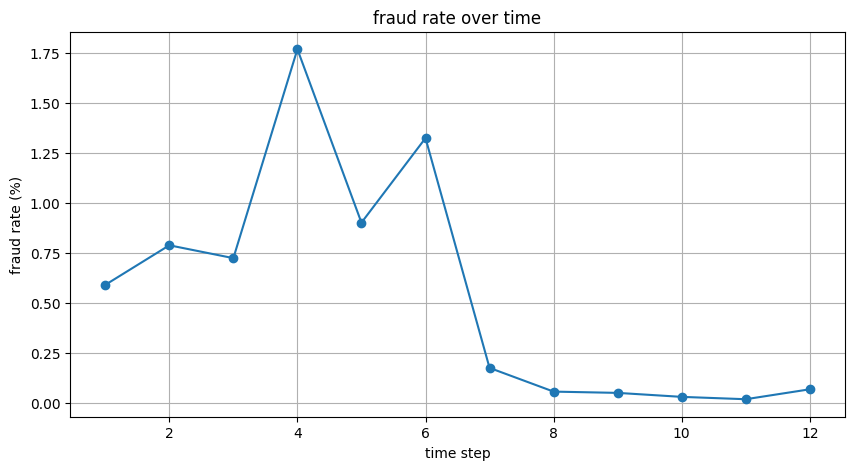

In [64]:
fraud_rate_by_step=df.groupby("step")["isFraud"].mean()*100
fraud_rate_by_step.plot(kind="line",marker="o",figsize=(10,5))
plt.title("fraud rate over time")
plt.xlabel("time step")
plt.ylabel("fraud rate (%)")
plt.grid(True)
plt.show()


# sender and receiver behavior analysis

in this observation C1709295811 appear  2 times and remaining 1 times appear

In [65]:
#count nameOrig
df["nameOrig"].value_counts().head(10)

,count
nameOrig,
C260230637,2
C44568807,2
C1709295811,2
C2064614971,1
C71897745,1
C1831903030,1
C2016722550,1
C883291771,1
C1284955877,1


in this observation
1. **most frequent receiver**: C985934102 appears in 79 times
2. other frequent receivers appear 59 and 77 times
3. somereceiver accounts may be coolection transaction from many senders. frequently used receiver is not automatically fraudulent it could be legimate account receiving many payments

In [66]:
#nameDest count
df["nameDest"].value_counts().head(10)

,count
nameDest,
C985934102,80
C1286084959,79
C1590550415,74
C248609774,74
C2083562754,71
C977993101,68
C665576141,67
C1360767589,64
C451111351,63


In [67]:
df[df["nameOrig"] == "C1709295811"]

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,amount_ratio,balance_change,balance_difference,amount_greater_than_balance,expected_balance,balance_mismatch
89078,10,TRANSFER,497725.93,C1709295811,0.0,0.00,C201995133,1033478.64,1531204.57,0.0,0.0,497725.9300,0.00,-4.977259e+05,True,-497725.93,True
115385,11,PAYMENT,17670.78,C1709295811,488136.0,470465.22,M356415752,0.00,0.00,0.0,0.0,0.0362,17670.78,2.910383e-11,False,470465.22,False


##Phase 2: Feature Selection and Data Preparation.

#Separate features and target

In [68]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud', 'amount_ratio', 'balance_change',
       'balance_difference', 'amount_greater_than_balance', 'expected_balance',
       'balance_mismatch'],
      dtype='object')

input

In [69]:
x=df[["step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"]]
print(x.head())

   step      type    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   PAYMENT   9839.64       170136.0       160296.36             0.0   
1     1   PAYMENT   1864.28        21249.0        19384.72             0.0   
2     1  TRANSFER    181.00          181.0            0.00             0.0   
3     1  CASH_OUT    181.00          181.0            0.00         21182.0   
4     1   PAYMENT  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  
0             0.0  
1             0.0  
2             0.0  
3             0.0  
4             0.0  


target

In [70]:
y=df["isFraud"]
print(y.head())

0    0.0
1    0.0
2    1.0
3    1.0
4    0.0
Name: isFraud, dtype: float64


**check the shape od input and target**:

1. in x rows are 83560 and 7 columns
2. rows 83560

In [71]:
print("x shape:",x.shape)
print("y shape:",y.shape)

x shape: (151798, 7)
y shape: (151798,)


check datatypes

* type is in object
* step in int
* amount,oldbalanceOrg, newbalanceOrig,oldbalanceDest,
newbalanceDest are in float

In [72]:
x.dtypes

,0
step,int64
type,object
amount,float64
oldbalanceOrg,float64
newbalanceOrig,float64
oldbalanceDest,float64
newbalanceDest,float64


#encode categorical feature
1. if i use label encoder, ordinal then model might interpret these number as having an number or numerical distance instead of assigning on number to each category i create a seprate column for each category

In [73]:
#x=pd.get_dummies(x,columns=["type"],dtype=int)
#print(x.head())

In [74]:
#verify
x.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0


#check feature redundancy:
* because oldbalanceorg and newbalanceorig
* oldbalanceDest and newbalanceDest

these are higly corelated features can sometimes provide overlapping info. i should investigate this before deciding

1. we can se they are highly correlated and +ve relation
2. old and new org 0.9989 positively correlated
3. old and new balancedest 0.9349 it also very strongly positvely correlated
4. amount and type_transfer are moderate positive relationship

5. oldbalance and type_cash_out 0.5606 positive relationship

In [75]:
#check coorelation
x.corr(numeric_only=True)

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
step,1.000000,0.061233,-0.006028,-0.005967,0.017574,0.004896
amount,0.061233,1.000000,-0.017959,-0.023204,0.229916,0.356693
oldbalanceOrg,-0.006028,-0.017959,1.000000,0.998955,0.096676,0.065992
newbalanceOrig,-0.005967,-0.023204,0.998955,1.000000,0.098159,0.064911
oldbalanceDest,0.017574,0.229916,0.096676,0.098159,1.000000,0.947677
newbalanceDest,0.004896,0.356693,0.065992,0.064911,0.947677,1.000000


**check the target distribution**

target feature are highly imbalanced
1. we need to focus this because model could predict every transaction as legimate and achive about 99% accuracy

In [76]:
y.value_counts()

,count
isFraud,
0.0,151667
1.0,131


#split the dataset into training and testing sets

Why use stratify=y?


Your dataset has only 112 fraudulent transactions out of 83,560. If we split randomly without stratification, the proportion of fraud cases could differ between the two sets.

stratify=y helps preserve approximately the same fraud-to-legitimate ratio in both sets.

In [77]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

y_train is imbalanced

In [78]:
print(y_train.value_counts())

isFraud
0.0    121333
1.0       105
Name: count, dtype: int64


#apply SMOTENC

SMOTE generates synthetic examples using numerical interpolation. It can create invalid fractional values if applied to one-hot encoded categories.



SMOTENC handles a mixture of numerical and categorical features, treating the categorical feature as a category rather than a continuous number.

* SMOTENC needs to know which column is categorical. In our seven-column X, type is at index 1 (the second column)

In [79]:
smotenc=SMOTENC(categorical_features=[1],random_state=42)

In [80]:
x_train_balnced,y_train_balnced=smotenc.fit_resample(x_train,y_train)

* noe target feature is balnced and equal

In [81]:
#check
print(y_train_balnced.value_counts())

isFraud
0.0    121333
1.0    121333
Name: count, dtype: int64


#encode type

In [82]:
x_train_balnced=pd.get_dummies(x_train_balnced,columns=["type"],dtype=int)
x_test=pd.get_dummies(x_test,columns=["type"],dtype=int)

In [83]:
x_test.head()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
15662,8,28920.50,342868.79,313948.29,0.00,0.00,0,0,0,1,0
20213,8,99379.80,34400.60,0.00,749858.58,366505.70,0,1,0,0,0
109592,11,13046.54,6684231.59,6697278.13,2743838.94,1974924.53,1,0,0,0,0
44818,9,352935.50,236324.00,0.00,69692.00,422627.50,0,1,0,0,0
100533,10,2742.72,88093.15,85350.43,0.00,0.00,0,0,0,1,0


**we need to verify or confirm that the training and testing data have exactly the same columns in the same order**:


*why it need*:
1. becuase when you apply SMOTENC features not match when you encode seprate train and test data

1. it verify training and testing fetures match

In [84]:
print(x_train_balnced.columns.equals(x_test.columns))

True


1. taining 242666 rows with 11 features per transaction


In [85]:
#check the shape
print("balanced training feature:",x_train_balnced.shape)
print("training target:",y_train_balnced.shape)

print("testing feature:",x_test.shape)
print("testing target:",y_test.shape)

balanced training feature: (242666, 11)
training target: (242666,)
testing feature: (30360, 11)
testing target: (30360,)


test fesutre are highly imbalnced

In [86]:
#check the test distribution
print(y_test.value_counts())

isFraud
0.0    30334
1.0       26
Name: count, dtype: int64


In [87]:
print("x_test:",x_test.shape)
print("y_test:",y_test.shape)

x_test: (30360, 11)
y_test: (30360,)


##Model Training and Evaluation

In [88]:
#create the model
lr=LogisticRegression(max_iter=1000,random_state=42)
lr.fit(x_train_balnced,y_train_balnced)

LogisticRegression(max_iter=1000, random_state=42)

1. 0 means the model predicts a legimate transaction
1. 1 means the model predicts a fradulent transaction

In [89]:
#predictions with logistic regressions
y_pred=lr.predict(x_test)
print(y_pred[:100])

[0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]


In [90]:
#Evaluate
print(pd.Series(y_pred).value_counts())

0.0    29029
1.0     1331
Name: count, dtype: int64


#evaluate the prediction

1. TN 18848: normal transaction correctly identified as normal
2. FN 574: model detect or identified normal transaction incorrectly  identified as fraud
3. FN 6: fraudulent transaction incorrectly identified as normal
4. TP 17: fraudulent transactions correctly indentified as fraud

* logistic regression model catches many fraudulent transaction but it also generate many false alarms

In [91]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[29024  1310]
 [    5    21]]


1. *precision*:
* **normal**:1.00 means nearly all transaction predicted as normal are actually normal
* **fraud**:0.03 means only about 3 out of 100 transaction flagged are fraud are actually fraudulent
2. *recall*:
  
* Normal: 0.97 means the model correctly identifies about 97% of actual normal transactions.
* Fraud: 0.74 means the model detects about 74% of actual fraud transactions.

3. F1-score:
This combines precision and recall into one score.
* Normal: 0.98 — strong performance for normal transactions.
* Fraud: 0.06 — poor overall balance between precision and recall for fraud detection

In [92]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

         0.0       1.00      0.96      0.98     30334
         1.0       0.02      0.81      0.03        26

    accuracy                           0.96     30360
   macro avg       0.51      0.88      0.50     30360
weighted avg       1.00      0.96      0.98     30360



test data contains only 22 fraud cases out of 16,712 transactions. Because fraud is extremely rare, a model can rank fraud cases relatively well (high ROC-AUC) but still perform poorly at identifying fraud without many false alarms.

The random-ranking baseline for Average Precision is approximately the fraud prevalence in the test set

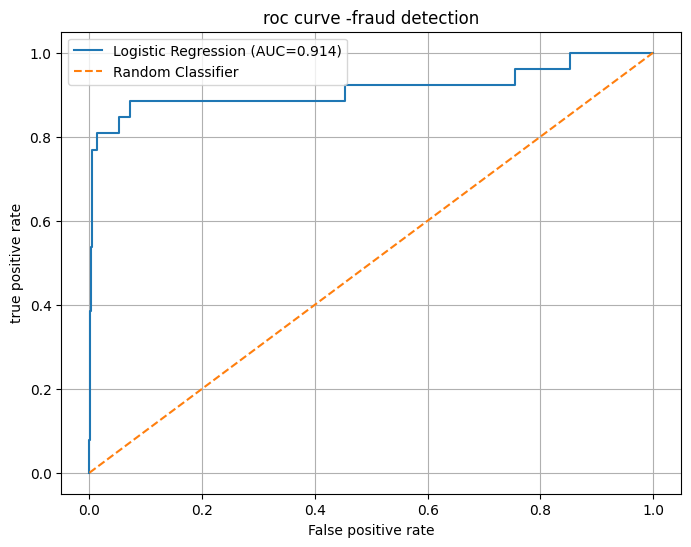

ROC-AUC Score: 0.9139313083567056


In [93]:
y_prob=lr.predict_proba(x_test)[:, 1]
#calculate roc values
fpr,tpr,thresholds=roc_curve(y_test,y_prob)
#calculate auc score
auc_score=roc_auc_score(y_test,y_prob)
#plot
plt.figure(figsize=(8,6))
plt.plot(fpr,tpr,label=f"Logistic Regression (AUC={auc_score:.3f})")
plt.plot([0,1],[0,1],linestyle="--",label="Random Classifier")
plt.xlabel("False positive rate")
plt.ylabel("true positive rate")
plt.title("roc curve -fraud detection")
plt.legend()
plt.grid(True)
plt.show()
print("ROC-AUC Score:", auc_score)

- X-axis (Recall): How many real fraud cases the model detects.
- Y-axis (Precision): How many transactions flagged as fraud are actually fraud.
that as recall increases toward 1.0, precision falls close to zero This means that when the model tries to catch nearly every fraud case it also flags many legitimate transactions

The high precision near the beginning of the curve applies to only a small number of highly ranked transactions

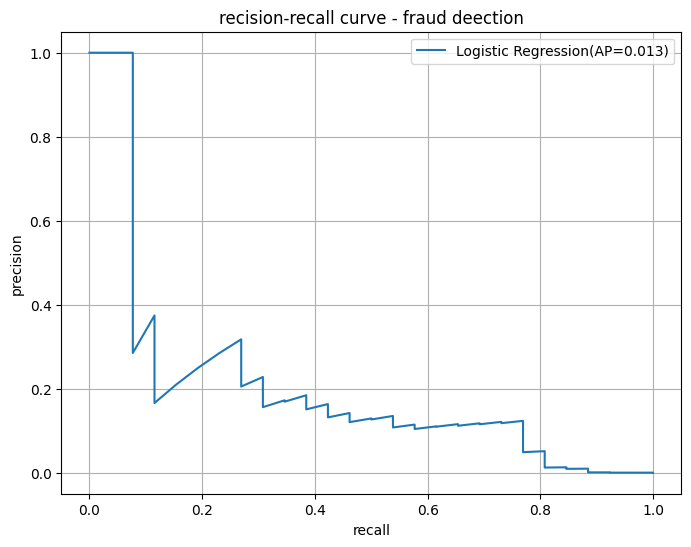

Average Precision: 0.01290814527429691


In [94]:
#calculate precision and recall
precision,recall,thresholds=precision_recall_curve(y_test,y_prob)
#calculate avg precision
ap_score=average_precision_score(y_test,y_pred)
#plot curve
plt.figure(figsize=(8,6))
plt.plot(recall,precision,label=f"Logistic Regression(AP={ap_score:.3f})")
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("recision-recall curve - fraud deection")
plt.legend()
plt.grid(True)
plt.show()
print("Average Precision:",ap_score)

Accuracy: 96.68% — most predictions are correct, but accuracy can be misleading because fraud is rare.



Precision: 2.14% — only about 2 out of every 100 transactions flagged as fraud are actually fraudulent.



Recall: 83.33% — the model detects about 83 out of every 100 actual fraud cases.



F1-score: 4.18% — precision is so low that the overall balance between precision and recall is poor.

In [95]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))

Accuracy: 0.9566864295125165
Precision: 0.015777610818933134
Recall: 0.8076923076923077
F1-score: 0.030950626381724394


In [96]:
y_train.value_counts()

,count
isFraud,
0.0,121333
1.0,105


In [97]:
print("Before balancing:")
print(y_train.value_counts())

print("\nAfter balancing:")
print(y_train_balnced.value_counts())

Before balancing:
isFraud
0.0    121333
1.0       105
Name: count, dtype: int64

After balancing:
isFraud
0.0    121333
1.0    121333
Name: count, dtype: int64


#Decision Tree

In [98]:
dtree=DecisionTreeClassifier(random_state=42)
dtree.fit(x_train_balnced,y_train_balnced)

DecisionTreeClassifier(random_state=42)

In [99]:
y_pred_dt=dtree.predict(x_test)

1. zero_division=0 tells Python what value to display when a metric cannot be calculated because its denominator is zero
2. If \(TP=0\) and \(FP=0\), the denominator is zero. With zero_division=0, Python displays precision as 0 instead of producing a warning about the undefined metric


*result*:
1. precision:0.30 about 30% of transaction flagged as fraud are actually fraudulent
2. recall: 0.62 the model detects about 62% of actual fraud cases
3. f1-score :0.41 balance precision and recall

- Logistic Regression catches a larger proportion of fraud cases, but generates more false alarms.



- Decision Tree has better precision and F1-score, but misses more fraud cases.

In [100]:
print(classification_report(y_test,y_pred_dt,zero_division=0))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     30334
         1.0       0.34      0.81      0.48        26

    accuracy                           1.00     30360
   macro avg       0.67      0.90      0.74     30360
weighted avg       1.00      1.00      1.00     30360



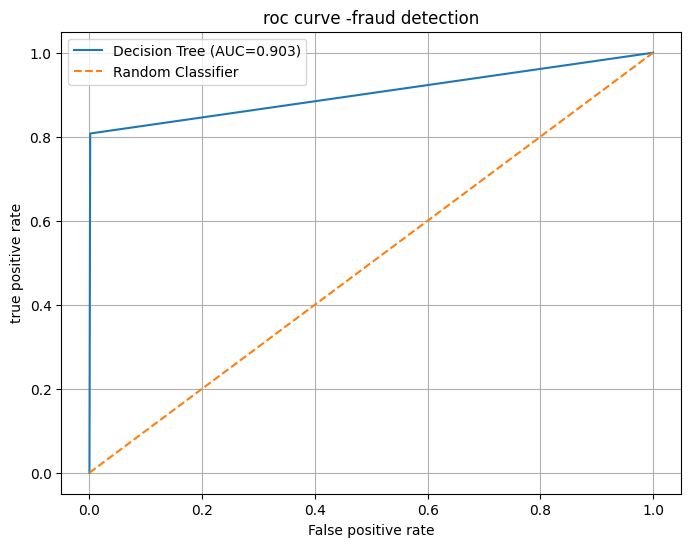

ROC-AUC Score: 0.9031868276774982


In [101]:
y_prob_dt=dtree.predict_proba(x_test)[:, 1]
#calculate roc values
fpr,tpr,thresholds=roc_curve(y_test,y_prob_dt)
#calculate auc score
auc_score=roc_auc_score(y_test,y_prob_dt)
#plot
plt.figure(figsize=(8,6))
plt.plot(fpr,tpr,label=f"Decision Tree (AUC={auc_score:.3f})")
plt.plot([0,1],[0,1],linestyle="--",label="Random Classifier")
plt.xlabel("False positive rate")
plt.ylabel("true positive rate")
plt.title("roc curve -fraud detection")
plt.legend()
plt.grid(True)
plt.show()
print("ROC-AUC Score:", auc_score)

#Random Forest

In [102]:
rf_model=RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)
rf_model.fit(x_train_balnced,y_train_balnced)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [103]:
y_pred_rf=rf_model.predict(x_test)

- Precision improved: 50% means half of the transactions flagged as fraud were actually fraudulent.
- Recall improved: The model detects 71% of actual fraud cases.
- F1-score improved: It provides a better balance between precision and recall than the Decision Tree.
- test set has only 24 fraud cases. A recall of 0.71 means the Random Forest detected approximately 17 of those cases

In [104]:
print(classification_report(y_test,y_pred_rf,zero_division=0))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     30334
         1.0       0.49      0.77      0.60        26

    accuracy                           1.00     30360
   macro avg       0.74      0.88      0.80     30360
weighted avg       1.00      1.00      1.00     30360



# XGBoost

In [105]:
!pip install xgboost

In [106]:
xgb_model=XGBClassifier(n_estimator=100,max_depth=6,learning_rate=0.1,random_state=42,eval_metric="logloss")
xgb_model.fit(x_train_balnced,y_train_balnced)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [09:36:43] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimator=100, n_estimators=None,
              n_jobs=None, ...)

- test set contains only 24 fraud cases. A recall of 0.79 means XGBoost detects approximately 19 out of 24 fraud cases

In [107]:
y_pred_xgb=xgb_model.predict(x_test)
print(classification_report(y_test,y_pred_xgb,zero_division=0))

              precision    recall  f1-score   support

         0.0       1.00      0.99      1.00     30334
         1.0       0.12      0.85      0.21        26

    accuracy                           0.99     30360
   macro avg       0.56      0.92      0.60     30360
weighted avg       1.00      0.99      1.00     30360



Random Forest currently has the best precision and F1-score among the results from the current test set.



XGBoost detects a larger proportion of fraud cases than Random Forest, but at the cost of more false alarms.



No model should be declared the final winner until we evaluate them on a consistent test set

#Isolation Forest

Anomaly:
1. looks for unusual patterns in transaction features
2. Isolation Forest builds random decision trees and tries to isolate each transaction. Unusual transactions often get isolated in fewer steps so they are more likely to be flagged as anomalies

3. the original unbalanced training data rather than SMOTENC-generated data.This is important because anomaly detection should learn the patterns present in the real transaction distribution

X_anomaly contains transaction details the algorithm will examine.



y_anomaly stores the actual labels so we can evaluate the results afterward.



We exclude isFraud so the model cannot use the answer while detecting anomalies.



We exclude account names because identifiers aren't useful numeric features for Isolation Forest.



We exclude isFlaggedFraud to avoid relying on an existing fraud flag.

**Why not use balanced data for Isolation Forest?**
Isolation Forest learns differently.
- Supervised models learn from the known labels isFraud, so balancing the training classes can help them learn fraud patterns.
- Isolation Forest looks for unusual patterns in the features. It doesn't need fraud labels during training.


In [108]:
x_anomaly=df.drop(columns=["isFraud","nameOrig","nameDest","isFlaggedFraud"])
y_anomaly=df["isFraud"]
print("features shape:",x_anomaly.shape)
print("labels shape:",y_anomaly.shape)

features shape: (151798, 13)
labels shape: (151798,)


*train the isloation algo*:training size is 80% and test size is 20%


In [109]:
x_train_anom,x_test_anom,y_train_anom,y_test_anom=train_test_split(x_anomaly,y_anomaly
                                                                   ,test_size=0.2,random_state=42,stratify=y_anomaly)

In [110]:
#check the shape
print(x_anomaly.shape)

(151798, 13)


In [111]:
x.shape

(151798, 7)

#encode the transaction type

pd.get_dummies() converts transaction categories into numeric columns.



reindex() ensures training and test data have the same columns in the same order.



We do not balance the data here; both sets retain their original class distribution

In [119]:
x_train_anom = pd.get_dummies(
    x_train_anom,
    columns=["type"],
    dtype=int
)
x_test_anom = pd.get_dummies(
    x_test_anom,
    columns=["type"],
    dtype=int
)
x_test_anom = x_test_anom.reindex(
    columns=x_train_anom.columns,
    fill_value=0
)
print("Remaining text columns:",
      x_train_anom.select_dtypes(include="object").columns.tolist())

print("Columns match:",
      x_train_anom.columns.equals(x_test_anom.columns))

Remaining text columns: []
Columns match: True


In [120]:
print("training shape:",x_train_anom.shape)
print("test shape:",x_test_anom.shape)
print("columns match:",x_train_anom.columns.equals(x_test_anom.columns))

training shape: (121438, 17)
test shape: (30360, 17)
columns match: True


In [121]:
print(x_train_anom.select_dtypes(include="object").columns.tolist())
print(x_train_anom.select_dtypes(include="object").columns.tolist())

[]
[]


In [122]:
print(x_train_anom.columns.tolist())

['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'amount_ratio', 'balance_change', 'balance_difference', 'amount_greater_than_balance', 'expected_balance', 'balance_mismatch', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


#train isolation forest

In [123]:
iso_model=IsolationForest(n_estimators=100,contamination="auto",random_state=42,n_jobs=-1)
iso_model.fit(x_train_anom)

IsolationForest(n_jobs=-1, random_state=42)

#predict anomalies

In [124]:
y_pred_iso=iso_model.predict(x_test_anom)


Isolation Forest returns:
- 1 = normal transaction
- -1 = anomaly
* convert those predictions to match your dataset's labels:
- 0 = predicted normal
- 1 = predicted anomaly

In [125]:
# Convert predictions into fraud-style labels
# Isolation Forest:  1 = normal, -1 = anomaly
y_pred_iso=(y_pred_iso==-1).astype(int)
print("predicted normal:",(y_pred_iso==0).sum())
print("predicted anomalies:",(y_pred_iso==1).sum())

predicted normal: 26647
predicted anomalies: 3713


#evaluate

True negatives (26,644): Normal transactions correctly identified.



False positives (3,690): Normal transactions incorrectly flagged as anomalies.



False negatives (3): Fraudulent transactions missed by the model.



True positives (23): Fraudulent transactions successfully detected

Isolation Forest detected most fraud cases, but it flagged thousands of legitimate transactions as anomalies. This means it is useful for identifying unusual patterns, but its current settings produce too many false alarms for practical fraud detection.

In [127]:
print("confusion matrix:")
print(confusion_matrix(y_test_anom,y_pred_iso))

confusion matrix:
[[26644  3690]
 [    3    23]]


Precision = 0.01: Only around 1% of the transactions flagged as anomalies are actually fraud.



Recall = 0.88: The model detects about 88% of the actual fraud cases.



F1-score = 0.01: The balance between precision and recall is poor because precision is extremely low

In [129]:
#classification report
print("classification report:")
print(classification_report(y_test_anom,y_pred_iso,zero_division=0))

classification report:
              precision    recall  f1-score   support

         0.0       1.00      0.88      0.94     30334
         1.0       0.01      0.88      0.01        26

    accuracy                           0.88     30360
   macro avg       0.50      0.88      0.47     30360
weighted avg       1.00      0.88      0.93     30360



#compare all models

Best F1-score: Random Forest (0.59). It has the best balance between precision and recall among the reported supervised-model results.



Best precision: Random Forest (0.50). Half of its fraud predictions are correct.



Best recall: Isolation Forest (0.8846). It catches the highest proportion of actual fraud cases in this comparison, but produces many false alarms.

In [131]:
comparison=pd.DataFrame({
    "model":[
        "LogisticRegression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Isolation Forest"
    ],
    "precision":[0.0214,0.30,0.50,0.18,23 / (23 + 3690)],
    "Recall": [0.8333, 0.62,0.71,0.79,23 / (23 + 3)],
    "F1-score": [0.0418,0.41,0.59,0.29,
        2 * (23 / (23 + 3690)) * (23 / (23 + 3))
        / ((23 / (23 + 3690)) + (23 / (23 + 3)))
    ]

})
print(comparison.round(4))

                model  precision  Recall  F1-score
0  LogisticRegression     0.0214  0.8333    0.0418
1       Decision Tree     0.3000  0.6200    0.4100
2       Random Forest     0.5000  0.7100    0.5900
3             XGBoost     0.1800  0.7900    0.2900
4    Isolation Forest     0.0062  0.8846    0.0123


#plot

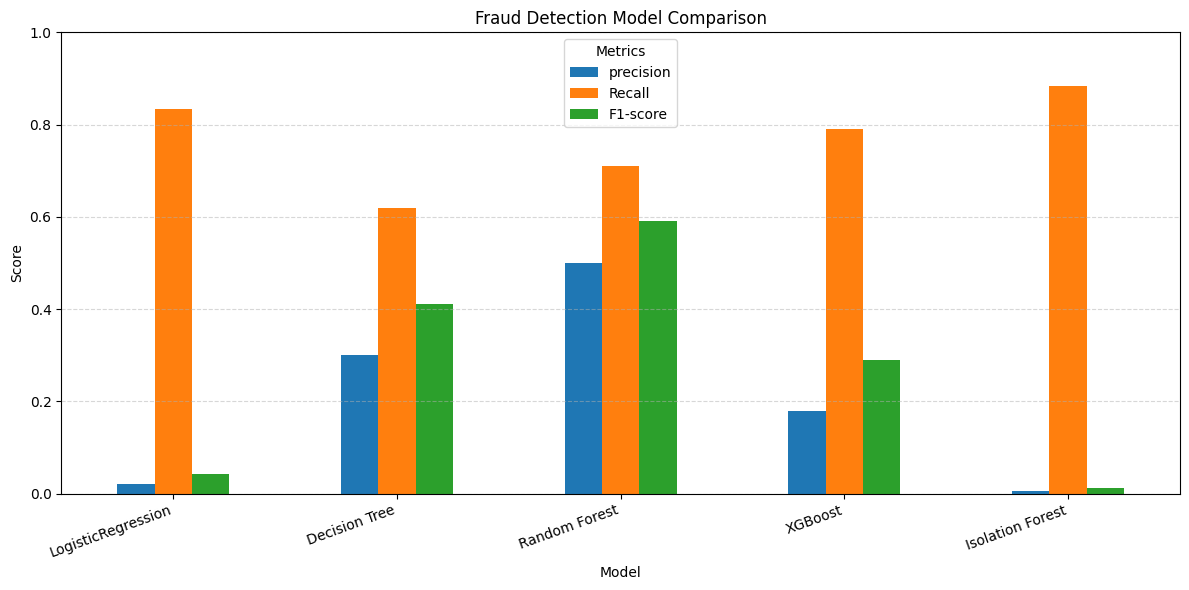

In [133]:
comparison.set_index("model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Fraud Detection Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()